<a href="https://colab.research.google.com/github/Ajijaumaira/Invoque_Titanic-survival-prediction-system-/blob/main/Titanic_Survival_Prediction_system.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

IMporting the Dependencies

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.m uhodel_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

Data Collection & processing

In [ ]:

# Loading the Titanic dataset
titanic_data = pd.read_csv(
    'https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv'
)

# Printing the first 5 rows
titanic_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
# number of rows and columns
titanic_data.shape

(891, 12)

In [ ]:
# getting some information about the data
titanic_data. cfinfo()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
# check the number of missing values in each column
titanic_data.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


Handling the Missing values

In [ ]:
# drop the "Cabin" column from the dataframe
titanic_data = titanic_data.drop(columns='Cabin', axis = 1)

In [ ]:
# replacing the missing values in "Age" column with mean value
titanic_data['Age'].fillna(titanic_data['Age'].mean(), inplace=True)

/tmp/ipykernel_1240/1542563166.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  titanic_data['Age'].fillna(titanic_data['Age'].mean(), inplace=True)


In [ ]:
# Finding the mode value of "Embarked" column
print(titanic_data['Embarked'].mode())

0    S
Name: Embarked, dtype: object


In [ ]:
print(titanic_data['Embarked'].mode())

0    S
Name: Embarked, dtype: object


In [ ]:
# Replacing missing values in "Embarked" with mode value
titanic_data['Embarked'].fillna(
    titanic_data['Embarked'].mode()[0],
    inplace=True
)

/tmp/ipykernel_1613/4053553881.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  titanic_data['Embarked'].fillna(


Data Analysis

In [ ]:
# Getting some statistical measures about the data
titanic_data.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,13.002015,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,29.699118,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:


# Finding the number of people survived and not survived
titanic_data['Survived'].value_counts()

,count
Survived,
0,549
1,342


Data Visualization

In [ ]:
sns.set()

<Axes: xlabel='Survived', ylabel='count'>

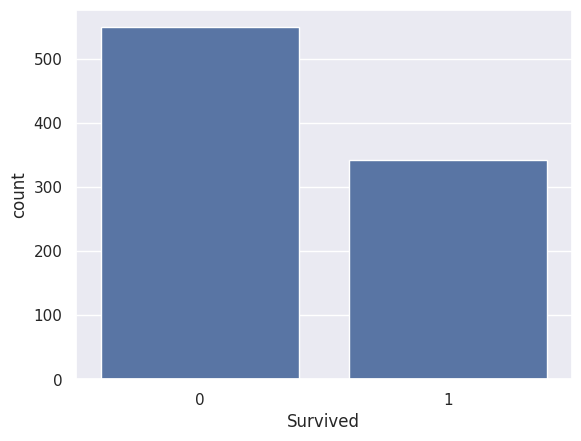

In [ ]:
# making a count plot for "Survived" column
sns.countplot(x="Survived", data=titanic_data)

<Axes: xlabel='Sex', ylabel='count'>

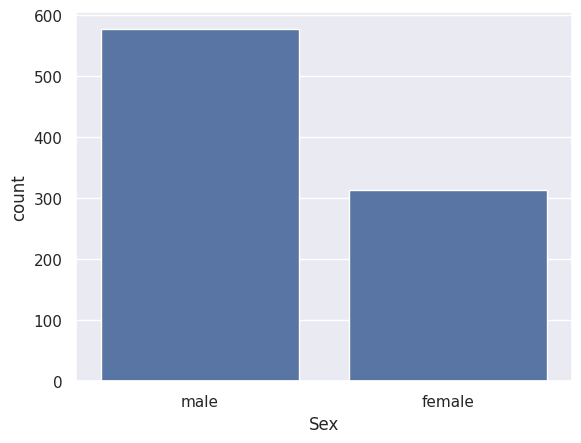

In [ ]:

# making a count plot for "Survived" column
sns.countplot(x="Sex", data=titanic_data)

<Axes: xlabel='Sex', ylabel='count'>

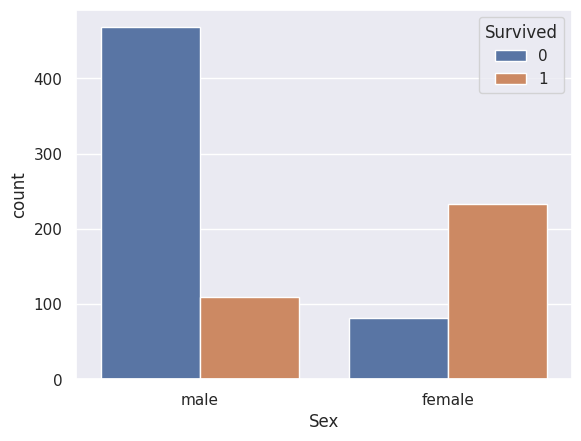

In [ ]:
# Number of survivors Gender wise
sns.countplot(x="Sex", hue="Survived", data=titanic_data)

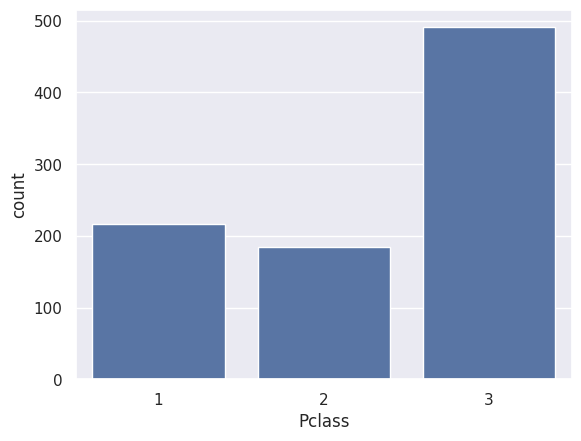

In [ ]:
# making a count plot for "Pclass" column
sns.countplot(x="Pclass", data=titanic_data)

plt.show()

<Axes: xlabel='Pclass', ylabel='count'>

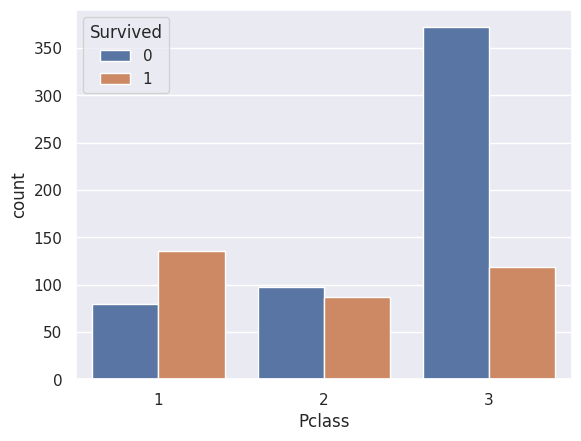

In [ ]:
sns.countplot(x="Pclass", hue="Survived", data=titanic_data)

Encoding the Categorical Columns

In [ ]:
titanic_data['Sex'].value_counts()

,count
Sex,
male,577
female,314


In [ ]:
titanic_data['Embarked'].value_counts()

,count
Embarked,
S,646
C,168
Q,77


In [ ]:
# converting categorical columns
titanic_data.replace({"Sex": {"male": 0, "female": 1},
                      "Embarked": {"S": 0, "C": 1, "Q": 2}},
                     inplace=True)

titanic_data.head()

/tmp/ipykernel_1240/1917309048.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  titanic_data.replace({"Sex": {"male": 0, "female": 1},


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",0,22.0,1,0,A/5 21171,7.2500,0.0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,38.0,1,0,PC 17599,71.2833,1.0
2,3,1,3,"Heikkinen, Miss. Laina",1,26.0,0,0,STON/O2. 3101282,7.9250,0.0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35.0,1,0,113803,53.1000,0.0
4,5,0,3,"Allen, Mr. William Henry",0,35.0,0,0,373450,8.0500,0.0


Separating features & Target

In [ ]:
X = titanic_data.drop(columns=['PassengerId', 'Name', 'Ticket', 'Survived'], axis=1)
Y = titanic_data['Survived']

In [ ]:
X.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,0,22.0,1,0,7.2500,0
1,1,1,38.0,1,0,71.2833,1
2,3,1,26.0,0,0,7.9250,0
3,1,1,35.0,1,0,53.1000,0
4,3,0,35.0,0,0,8.0500,0


In [ ]:
Y.head()

,Survived
0,0
1,1
2,1
3,1
4,0


Splitting the data into training data & Test data

In [ ]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=2
)

In [ ]:
print(X.shape, X_train.shape, X_test.shape)

(891, 7) (712, 7) (179, 7)


Model Training

Logistic Regression

In [ ]:
model = LogisticRegression()

In [ ]:
# Training the Logistic Regression model with training data
model.fit(X_train, Y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

Model Evaluation

Accuracy Score

In [ ]:
# accuracy on training data
X_train_prediction = model.predict(X_train)

In [ ]:
print(X_train_prediction)

[0 1 0 0 0 0 0 1 0 0 0 1 0 0 1 0 1 0 0 0 0 0 1 0 0 1 0 0 1 0 1 1 0 0 1 0 1
 0 0 0 0 0 0 1 1 0 0 1 0 1 0 1 0 0 0 0 0 0 1 0 1 0 0 1 1 0 0 1 1 0 1 0 0 1
 0 0 0 0 0 0 1 0 0 0 1 0 0 0 1 0 1 0 0 1 0 0 0 1 1 1 0 1 0 0 0 0 0 1 0 0 0
 1 1 0 0 1 0 0 1 0 0 1 0 0 1 0 1 0 1 0 1 0 1 1 1 1 1 1 0 0 1 1 1 0 0 1 0 0
 0 0 0 0 1 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 1 0 0 1 0 1 0 1 1 1
 0 0 0 1 0 0 0 1 0 0 1 0 0 0 1 1 0 1 0 0 0 0 0 1 1 0 1 1 1 1 0 0 0 0 0 0 0
 0 1 0 0 1 1 1 0 0 1 0 1 1 1 0 0 1 0 0 0 0 1 0 0 0 1 0 0 0 1 0 1 0 1 0 0 0
 0 0 0 0 0 0 1 0 1 0 0 1 0 0 1 0 1 0 1 1 0 0 0 0 1 0 1 0 0 1 0 0 0 1 0 0 0
 0 1 1 0 0 0 0 0 0 1 0 1 0 0 0 0 0 1 1 1 0 0 0 1 0 1 0 0 0 0 0 0 1 1 0 1 1
 0 1 1 1 0 0 0 0 0 0 0 0 0 1 0 0 1 1 1 0 1 0 0 0 0 1 1 0 0 0 1 0 1 1 1 0 0
 0 0 1 0 0 0 1 1 0 0 1 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 1 0 1 1 1 0 1 1 0 0 0
 0 1 0 1 0 0 1 1 0 0 0 0 1 0 0 0 0 1 1 0 1 0 1 0 0 0 0 0 1 0 0 0 0 1 1 0 0
 1 0 1 0 0 1 0 0 0 0 0 0 0 0 1 0 0 1 1 0 0 0 1 1 0 1 0 0 1 0 0 0 1 1 0 1 0
 0 0 0 0 1 0 0 1 0 1 1 0 

In [ ]:
training_data_accuracy = accuracy_score(Y_train, X_train_prediction)

print("Accuracy score of training data : ", training_data_accuracy)

Accuracy score of training data :  0.8075842696629213


In [ ]:
# accuracy on test data
X_test_prediction = model.predict(X_test)

In [ ]:
print(X_test_prediction)

[0 0 1 0 0 0 0 0 0 0 0 1 1 0 0 1 0 0 1 0 1 1 0 1 0 1 1 0 0 0 0 0 0 0 0 1 1
 0 0 0 0 0 1 0 0 1 1 0 0 1 0 0 0 0 0 0 1 0 0 0 1 0 0 0 1 0 1 0 0 0 1 0 1 0
 1 0 0 0 1 0 1 0 0 0 1 1 0 0 1 0 0 0 0 0 0 1 0 1 0 0 1 0 1 1 0 1 1 0 0 0 0
 0 0 0 1 1 0 1 0 0 1 0 0 0 0 0 0 1 0 0 0 0 1 1 0 0 0 0 0 0 1 1 1 1 0 1 0 0
 0 1 0 0 0 0 1 0 0 1 1 0 1 0 0 0 1 1 0 0 1 0 0 1 1 1 0 0 0 0 0]


In [ ]:
test_data_accuracy = accuracy_score(Y_test, X_test_prediction)

print("Accuracy score of test data : ", test_data_accuracy)

Accuracy score of test data :  0.7821229050279329


In [ ]:
print(X.isnull().sum())

Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    2
dtype: int64


In [ ]:
# Recreate training and testing data after handling missing values

X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=2
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nMissing values in X_train:")
print(X_train.isnull().sum())

print("\nMissing values in X_test:")
print(X_test.isnull().sum())

Training data shape: (712, 7)
Testing data shape: (179, 7)

Missing values in X_train:
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

Missing values in X_test:
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


In [ ]:
# Fill missing values in Embarked with the mode
X['Embarked'] = X['Embarked'].fillna(X['Embarked'].mode()[0])

# Check missing values again
print(X.isnull().sum())

Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


In [ ]:
# ============================================================
# TRAIN 3 MACHINE LEARNING MODELS
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score


# Logistic Regression
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train, Y_train)

lr_prediction = logistic_model.predict(X_test)
lr_accuracy = accuracy_score(Y_test, lr_prediction)

print("Logistic Regression Accuracy:", lr_accuracy)


# Decision Tree
decision_tree = DecisionTreeClassifier(random_state=42)
decision_tree.fit(X_train, Y_train)

dt_prediction = decision_tree.predict(X_test)
dt_accuracy = accuracy_score(Y_test, dt_prediction)

print("Decision Tree Accuracy:", dt_accuracy)


# Random Forest
random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
random_forest.fit(X_train, Y_train)

rf_prediction = random_forest.predict(X_test)
rf_accuracy = accuracy_score(Y_test, rf_prediction)

print("Random Forest Accuracy:", rf_accuracy)

Logistic Regression Accuracy: 0.7821229050279329
Decision Tree Accuracy: 0.7877094972067039
Random Forest Accuracy: 0.8044692737430168


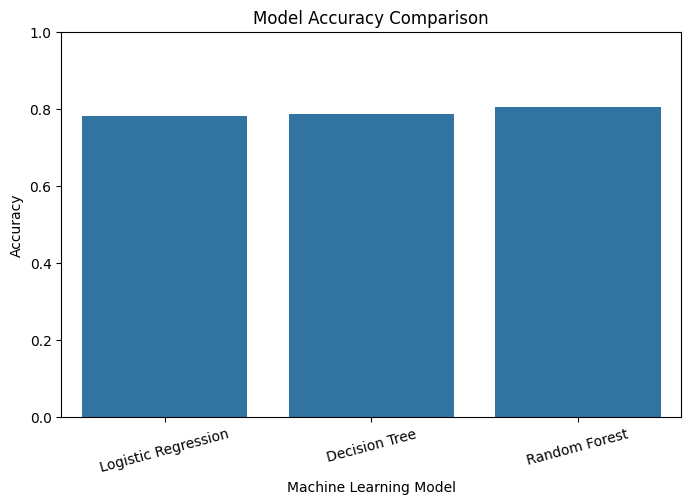

In [ ]:
# ============================================================
# MODEL ACCURACY COMPARISON
# ============================================================

model_names = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest"
]

accuracies = [
    lr_accuracy,
    dt_accuracy,
    rf_accuracy
]

plt.figure(figsize=(8, 5))

sns.barplot(
    x=model_names,
    y=accuracies
)

plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")
plt.title("Model Accuracy Comparison")

plt.ylim(0, 1)
plt.xticks(rotation=15)

plt.show()

In [ ]:
# ============================================================
# MODEL EVALUATION - PRECISION, RECALL AND F1 SCORE
# ============================================================

from sklearn.metrics import precision_score, recall_score, f1_score

# Logistic Regression
print("===== Logistic Regression =====")

print("Precision:",
      precision_score(Y_test, lr_prediction, zero_division=0))

print("Recall:",
      recall_score(Y_test, lr_prediction, zero_division=0))

print("F1 Score:",
      f1_score(Y_test, lr_prediction, zero_division=0))


# Decision Tree
print("\n===== Decision Tree =====")

print("Precision:",
      precision_score(Y_test, dt_prediction, zero_division=0))

print("Recall:",
      recall_score(Y_test, dt_prediction, zero_division=0))

print("F1 Score:",
      f1_score(Y_test, dt_prediction, zero_division=0))


# Random Forest
print("\n===== Random Forest =====")

print("Precision:",
      precision_score(Y_test, rf_prediction, zero_division=0))

print("Recall:",
      recall_score(Y_test, rf_prediction, zero_division=0))

print("F1 Score:",
      f1_score(Y_test, rf_prediction, zero_division=0))

===== Logistic Regression =====
Precision: 0.8448275862068966
Recall: 0.620253164556962
F1 Score: 0.7153284671532847

===== Decision Tree =====
Precision: 0.7808219178082192
Recall: 0.7215189873417721
F1 Score: 0.75

===== Random Forest =====
Precision: 0.8142857142857143
Recall: 0.7215189873417721
F1 Score: 0.7651006711409396


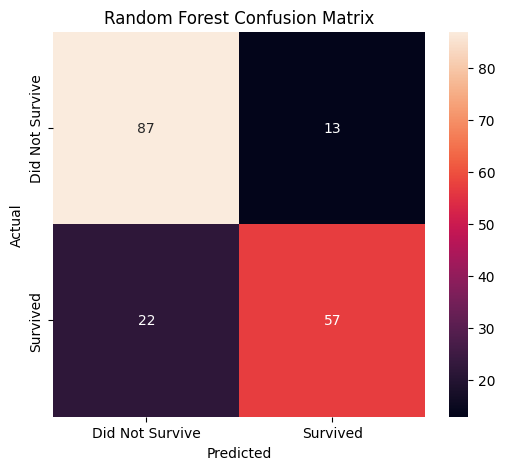

In [ ]:
# ============================================================
# CONFUSION MATRIX - RANDOM FOREST
# ============================================================

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(Y_test, rf_prediction)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Did Not Survive", "Survived"],
    yticklabels=["Did Not Survive", "Survived"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.show()

In [ ]:
# ============================================================
# CLASSIFICATION REPORT - RANDOM FOREST
# ============================================================

from sklearn.metrics import classification_report

print("===== Random Forest Classification Report =====")

print(
    classification_report(
        Y_test,
        rf_prediction,
        target_names=["Did Not Survive", "Survived"],
        zero_division=0
    )
)

===== Random Forest Classification Report =====
                 precision    recall  f1-score   support

Did Not Survive       0.80      0.87      0.83       100
       Survived       0.81      0.72      0.77        79

       accuracy                           0.80       179
      macro avg       0.81      0.80      0.80       179
   weighted avg       0.81      0.80      0.80       179



In [ ]:
# ============================================================
# SAMPLE PREDICTION RESULTS
# ============================================================

print("===== SAMPLE PREDICTION RESULTS =====")

actual_values = np.asarray(Y_test)
predicted_values = np.asarray(rf_prediction)

number_of_predictions = min(10, len(actual_values))

for i in range(number_of_predictions):

    actual_result = (
        "Survived"
        if actual_values[i] == 1
        else "Did Not Survive"
    )

    predicted_result = (
        "Survived"
        if predicted_values[i] == 1
        else "Did Not Survive"
    )

    print(
        f"Passenger {i + 1}: "
        f"Actual = {actual_result}, "
        f"Predicted = {predicted_result}"
    )

===== SAMPLE PREDICTION RESULTS =====
Passenger 1: Actual = Survived, Predicted = Survived
Passenger 2: Actual = Did Not Survive, Predicted = Did Not Survive
Passenger 3: Actual = Survived, Predicted = Survived
Passenger 4: Actual = Did Not Survive, Predicted = Did Not Survive
Passenger 5: Actual = Survived, Predicted = Did Not Survive
Passenger 6: Actual = Did Not Survive, Predicted = Did Not Survive
Passenger 7: Actual = Survived, Predicted = Did Not Survive
Passenger 8: Actual = Did Not Survive, Predicted = Did Not Survive
Passenger 9: Actual = Survived, Predicted = Did Not Survive
Passenger 10: Actual = Did Not Survive, Predicted = Did Not Survive


In [ ]:
# ============================================================
# STEP 14 - FINAL MODEL COMPARISON TABLE
# ============================================================

final_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        lr_accuracy,
        dt_accuracy,
        rf_accuracy
    ],
    "Precision": [
        precision_score(Y_test, lr_prediction, zero_division=0),
        precision_score(Y_test, dt_prediction, zero_division=0),
        precision_score(Y_test, rf_prediction, zero_division=0)
    ],
    "Recall": [
        recall_score(Y_test, lr_prediction, zero_division=0),
        recall_score(Y_test, dt_prediction, zero_division=0),
        recall_score(Y_test, rf_prediction, zero_division=0)
    ],
    "F1 Score": [
        f1_score(Y_test, lr_prediction, zero_division=0),
        f1_score(Y_test, dt_prediction, zero_division=0),
        f1_score(Y_test, rf_prediction, zero_division=0)
    ]
})

# Round values to 4 decimal places
final_results = final_results.round(4)

display(final_results)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.7821,0.8448,0.6203,0.7153
1,Decision Tree,0.7877,0.7808,0.7215,0.7500
2,Random Forest,0.8045,0.8143,0.7215,0.7651
